# 03 - Measurement analysis with rfmeasurement

Apply the SOL terms to measurements, validate the corrected networks, and generate result plots.

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import skrf as rf
from rfmeasurement.domain import Measurement, MeasurementContext
from rfmeasurement.validation import validate

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
TERMS = np.load(ROOT / 'results' / 'error_terms_SOL_master.npz')
MEASURE_ROOT = ROOT / 'data' / 'measures'

def correct_gamma(gamma_m):
    freqs = TERMS['freqs_hz']
    ed = np.interp(freqs, freqs, TERMS['ed'].real) + 1j * np.interp(freqs, freqs, TERMS['ed'].imag)
    er = np.interp(freqs, freqs, TERMS['er'].real) + 1j * np.interp(freqs, freqs, TERMS['er'].imag)
    es = np.interp(freqs, freqs, TERMS['es'].real) + 1j * np.interp(freqs, freqs, TERMS['es'].imag)
    return (gamma_m - ed) / (er + es * gamma_m)

def validate_corrected(path):
    network = rf.Network(path)
    network.s[:, 0, 0] = correct_gamma(network.s[:, 0, 0])
    measurement = Measurement(
        data=network,
        context=MeasurementContext(
            dut=f'corrected:{path.stem}',
            instrument='NanoVNA',
            calibration='SOL',
        ),
    )
    return network, validate(measurement)

/Users/telmomm/Library/CloudStorage/OneDrive-Personal/DOCENCIA/INVESTIGACION/NanoVNA Calibration/data/measures/att -10db (18)/test_1.s2p FAIL warnings= True
/Users/telmomm/Library/CloudStorage/OneDrive-Personal/DOCENCIA/INVESTIGACION/NanoVNA Calibration/data/measures/att -10db (18)/test_2.s2p FAIL warnings= True
/Users/telmomm/Library/CloudStorage/OneDrive-Personal/DOCENCIA/INVESTIGACION/NanoVNA Calibration/data/measures/att -10db (18)/test_3.s2p FAIL warnings= True
/Users/telmomm/Library/CloudStorage/OneDrive-Personal/DOCENCIA/INVESTIGACION/NanoVNA Calibration/data/measures/att -5db (17)/test_1.s2p FAIL warnings= True
/Users/telmomm/Library/CloudStorage/OneDrive-Personal/DOCENCIA/INVESTIGACION/NanoVNA Calibration/data/measures/att -5db (17)/test_2.s2p FAIL warnings= True
/Users/telmomm/Library/CloudStorage/OneDrive-Personal/DOCENCIA/INVESTIGACION/NanoVNA Calibration/data/measures/att -5db (17)/test_3.s2p FAIL warnings= True
/Users/telmomm/Library/CloudStorage/OneDrive-Personal/DOCENCI

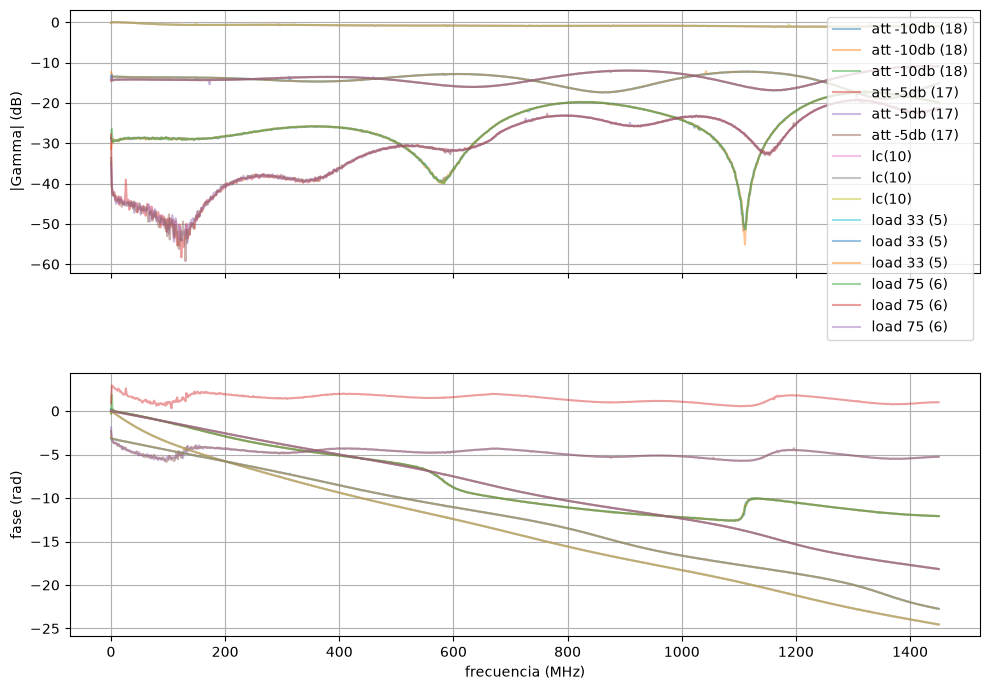

In [5]:
files = sorted(MEASURE_ROOT.rglob('*.s2p'))
if not files:
    raise FileNotFoundError(f'No hay medidas en {MEASURE_ROOT}')

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7))
for path in files:
    network, report = validate_corrected(path)
    gamma = network.s[:, 0, 0]
    axes[0].plot(network.f / 1e6, 20 * np.log10(np.maximum(np.abs(gamma), 1e-15)), alpha=0.45, label=path.parent.name)
    axes[1].plot(network.f / 1e6, np.unwrap(np.angle(gamma)), alpha=0.45)
    print(path, 'FAIL' if report.has_failures else 'OK', 'warnings=', report.has_warnings)
axes[0].set_ylabel('|Gamma| (dB)'); axes[1].set_ylabel('fase (rad)'); axes[1].set_xlabel('frecuencia (MHz)')
axes[0].grid(True); axes[1].grid(True); axes[0].legend()
plt.tight_layout(); plt.show()